In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
appointments = pd.read_csv(
    "../data/raw/apollo_appointments_fact.csv"
)

doctors = pd.read_csv(
    "../data/raw/apollo_doctors_dim.csv"
)

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [4]:
print("Appointments:", appointments.shape)
print("Doctors:", doctors.shape)

Appointments: (75000, 52)
Doctors: (320, 15)


In [5]:
appointments.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,...,No,NaN,0,2700,2700,UPI,11.0,40.0,4.8,84.2
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,...,No,NaN,0,1400,1400,UPI,21.0,18.0,4.1,64.5
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,...,No,NaN,0,600,600,Net Banking,6.0,6.0,5.0,75.6
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,...,No,NaN,0,1275,1275,UPI,2.0,25.0,4.4,68.6
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,...,No,NaN,0,1700,1700,Cash,7.0,13.0,3.5,67.7


In [6]:
doctors.head()

,doctor_id,doctor_name,specialty,qualification,experience_years,city,state,hospital_name,consultation_fee,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,DOC1001,Dr. Deepa Sharma,Urology,"MBBS, MCh",12,Bengaluru,Karnataka,Apollo Hospital Bannerghatta,2300,4.4,1502,Mon-Fri,15,Yes,No
1,DOC1002,Dr. Venkatesan Khan,Paediatrics,"MBBS, MS, FRCS",25,Chandigarh,Punjab,Apollo Clinic Sector 8,1200,4.5,2453,Mon-Sat,10,Yes,Yes
2,DOC1003,Dr. Pradeep Menon,General Physician,"MBBS, DM",13,Mumbai,Maharashtra,Apollo Clinic Andheri,700,4.7,995,Mon-Wed-Fri-Sat,15,No,No
3,DOC1004,Dr. Vivek Mathew,General Physician,"MBBS, MD",31,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,1000,4.9,666,Mon-Wed-Fri-Sat,20,Yes,Yes
4,DOC1005,Dr. Savita Philip,General Physician,"MBBS, MD, PhD",5,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,600,4.5,1383,Mon-Sat,30,Yes,Yes


In [7]:
appointments.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  str    
 1   patient_id                  75000 non-null  str    
 2   doctor_id                   75000 non-null  str    
 3   appointment_date            75000 non-null  str    
 4   appointment_day             75000 non-null  str    
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  str    
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  str    
 12  time_of_day                 75000 non-null  str    
 13  booking_date                75000 non-null

In [8]:
doctors.info()

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   doctor_id              320 non-null    str    
 1   doctor_name            320 non-null    str    
 2   specialty              320 non-null    str    
 3   qualification          320 non-null    str    
 4   experience_years       320 non-null    int64  
 5   city                   320 non-null    str    
 6   state                  320 non-null    str    
 7   hospital_name          320 non-null    str    
 8   consultation_fee       320 non-null    int64  
 9   rating                 320 non-null    float64
 10  total_reviews          320 non-null    int64  
 11  available_days         320 non-null    str    
 12  avg_slot_duration_min  320 non-null    int64  
 13  accepts_insurance      320 non-null    str    
 14  teleconsult_enabled    320 non-null    str    
dtypes: float64(1), in

In [9]:
appointments.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
appointment_id,75000,75000,APPT5000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_id,75000,32705,PAT108111,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doctor_id,75000,320,DOC1247,419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_date,75000,1096,2023-01-29,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_day,75000,7,Sunday,10930,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_day_of_week,75000.0,NaN,NaN,NaN,3.011293,2.002377,0.0,1.0,3.0,5.0,6.0
appointment_month,75000.0,NaN,NaN,NaN,6.554253,3.571468,1.0,3.0,7.0,10.0,12.0
appointment_quarter,75000,4,Q4,20642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_year,75000.0,NaN,NaN,NaN,2023.0028,0.816056,2022.0,2022.0,2023.0,2024.0,2024.0
appointment_hour,75000.0,NaN,NaN,NaN,12.757,3.42647,8.0,10.0,12.0,16.0,19.0


In [10]:
missing = pd.DataFrame({
    "Missing_Count": appointments.isnull().sum(),
    "Missing_Percentage": (
        appointments.isnull().mean() * 100
    )
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing)

                            Missing_Count  Missing_Percentage
cancellation_reason                 69207           92.276000
membership_type                     58225           77.633333
insurance_provider                  51512           68.682667
patient_chronic_condition           28038           37.384000
wait_time_minutes                   19725           26.300000
consultation_duration_min           19725           26.300000
patient_satisfaction_score          19725           26.300000
doctor_utilization_pct              19725           26.300000
no_show                              2348            3.130667
appointment_year                        0            0.000000
appointment_minute                      0            0.000000
appointment_hour                        0            0.000000
appointment_day                         0            0.000000
appointment_day_of_week                 0            0.000000
appointment_month                       0            0.000000
appointm

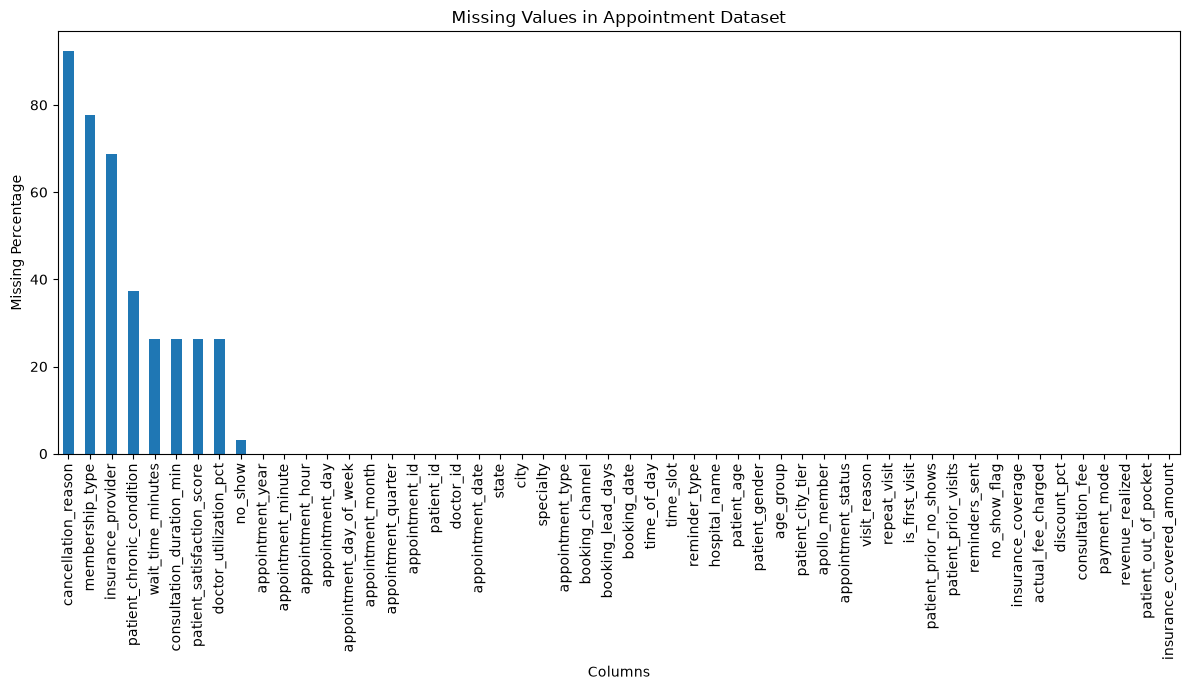

In [11]:
plt.figure(figsize=(12, 7))

missing["Missing_Percentage"].plot(kind="bar")

plt.title("Missing Values in Appointment Dataset")
plt.ylabel("Missing Percentage")
plt.xlabel("Columns")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [12]:
appointments["membership_type"] = (
    appointments["membership_type"].fillna("Unknown")
)

In [14]:
cols_to_check = [
    "cancellation_reason",
    "membership_type",
    "insurance_provider",
    "patient_chronic_condition",
    "wait_time_minutes",
    "consultation_duration_min",
    "patient_satisfaction_score",
    "doctor_utilization_pct",
    "no_show"
]

missing_by_status = appointments.groupby(
    "appointment_status"
)[cols_to_check].apply(
    lambda x: x.isnull().mean() * 100
)

print(missing_by_status.round(2))

                    cancellation_reason  membership_type  insurance_provider  \
appointment_status                                                             
Cancelled                           0.0              0.0               68.34   
Completed                         100.0              0.0               67.88   
No-Show                           100.0              0.0               72.49   
Scheduled                         100.0              0.0               69.55   

                    patient_chronic_condition  wait_time_minutes  \
appointment_status                                                 
Cancelled                               38.60              100.0   
Completed                               37.26                0.0   
No-Show                                 37.24              100.0   
Scheduled                               38.07              100.0   

                    consultation_duration_min  patient_satisfaction_score  \
appointment_status               

In [15]:
completed_appointments = appointments[
    appointments["appointment_status"] == "Completed"
]

print(
    completed_appointments[
        [
            "wait_time_minutes",
            "consultation_duration_min",
            "patient_satisfaction_score",
            "doctor_utilization_pct"
        ]
    ].isnull().sum()
)

wait_time_minutes             0
consultation_duration_min     0
patient_satisfaction_score    0
doctor_utilization_pct        0
dtype: int64


In [16]:
print(
    pd.crosstab(
        appointments["insurance_coverage"],
        appointments["insurance_provider"].isnull(),
        margins=True
    )
)

insurance_provider  False   True    All
insurance_coverage                     
No                      0  51512  51512
Yes                 23488      0  23488
All                 23488  51512  75000


In [17]:
print(
    pd.crosstab(
        appointments["appointment_status"],
        appointments["no_show_flag"]
    )
)

no_show_flag            0      1
appointment_status              
Cancelled            5793      0
Completed           55275      0
No-Show                 0  11584
Scheduled            2348      0


In [18]:
print(
    pd.crosstab(
        appointments["no_show"],
        appointments["no_show_flag"],
        dropna=False
    )
)

no_show_flag      0      1
no_show                   
No            61068      0
Yes               0  11584
NaN            2348      0


In [19]:
# Create a cleaned copy
cleaned_appointments = appointments.copy()

# Handle categorical missing values
cleaned_appointments["insurance_provider"] = (
    cleaned_appointments["insurance_provider"].fillna("Not Insured")
)

cleaned_appointments["patient_chronic_condition"] = (
    cleaned_appointments["patient_chronic_condition"].fillna("Unknown")
)

# Check remaining missing values
print(cleaned_appointments.isnull().sum())

appointment_id                    0
patient_id                        0
doctor_id                         0
appointment_date                  0
appointment_day                   0
appointment_day_of_week           0
appointment_month                 0
appointment_quarter               0
appointment_year                  0
appointment_hour                  0
appointment_minute                0
time_slot                         0
time_of_day                       0
booking_date                      0
booking_lead_days                 0
booking_channel                   0
appointment_type                  0
specialty                         0
city                              0
state                             0
hospital_name                     0
patient_age                       0
age_group                         0
patient_gender                    0
patient_city_tier                 0
patient_chronic_condition         0
apollo_member                     0
membership_type             